# CocoCare — Healthy Coconut Dataset Audit & Integration

**Purpose:** inspect the downloaded datasets under `ml/data/raw`, identify candidate healthy coconut images, review them, detect exact duplicates, and (only after manual confirmation) prepare a six-class dataset for MobileNetV3Small.

## Important safeguards
- This notebook does **not** modify or delete the original datasets.
- It does not automatically assume that a green-looking image is healthy.
- Only images in folders explicitly labelled `healthy` (or manually approved in the mapping cell) are candidates.
- Whole-tree/crown images and close-up leaf images are tracked separately.
- Do not use generated/augmented copies across train/validation/test splits.
- Review dataset licences and attribution before research or publication use.

### Expected raw-data layout

Based on your screenshot:

```text
CocoCare/ml/data/raw/
├── coconut_leaf_disease_data/
├── kaggle/
├── mendeley/
└── datasetDownload.py
```

Run this notebook from `CocoCare/ml/` or update `RAW_DATA_DIR` in the next cell.

## 1. Imports and paths

In [3]:
# Project paths
from pathlib import Path

# Notebook is inside CocoCare/ml/notebooks/
PROJECT_ROOT = Path.cwd()

# Automatically locate the ml directory
if PROJECT_ROOT.name == "notebooks":
    ML_ROOT = PROJECT_ROOT.parent
elif PROJECT_ROOT.name == "ml":
    ML_ROOT = PROJECT_ROOT
elif (PROJECT_ROOT / "ml").is_dir():
    ML_ROOT = PROJECT_ROOT / "ml"
else:
    raise FileNotFoundError("Could not locate the CocoCare/ml directory.")

# Dataset directories
RAW_DATA_DIR = ML_ROOT / "data" / "raw"

PREPARED_DIR = ML_ROOT / "data" / "processed" / "coconut_health_v2"

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".webp", ".tif", ".tiff"
}

print("Project root:", ML_ROOT.parent.resolve())
print("ML directory:", ML_ROOT.resolve())
print("Raw dataset:", RAW_DATA_DIR.resolve())
print("Prepared dataset:", PREPARED_DIR.resolve())
print("Raw dataset exists:", RAW_DATA_DIR.exists())

if not RAW_DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset directory not found: {RAW_DATA_DIR}"
    )

Project root: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare
ML directory: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml
Raw dataset: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/data/raw
Prepared dataset: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/data/processed/coconut_health_v2
Raw dataset exists: True


## 2. Inspect the top-level folders

In [4]:
for item in sorted(RAW_DATA_DIR.iterdir()):
    kind = "DIR " if item.is_dir() else "FILE"
    print(f"{kind}  {item.name}")

DIR   coconut_leaf_disease_data
FILE  datasetDownlaod.py
DIR   kaggle
DIR   mendeley


## 3. Inventory image files

This scans recursively and records the source folder, relative path, image dimensions and file size. It does not infer health labels.

In [5]:
records = []
unreadable = []

for path in RAW_DATA_DIR.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    rel = path.relative_to(RAW_DATA_DIR)
    parts = rel.parts
    source_group = parts[0] if parts else "unknown"

    try:
        with Image.open(path) as im:
            width, height = im.size
            mode = im.mode
            im.verify()

        records.append({
            "path": str(path.resolve()),
            "relative_path": str(rel),
            "source_group": source_group,
            "parent_folder": path.parent.name,
            "filename": path.name,
            "extension": path.suffix.lower(),
            "width": width,
            "height": height,
            "mode": mode,
            "file_size_bytes": path.stat().st_size,
        })
    except Exception as exc:
        unreadable.append({"path": str(path), "error": str(exc)})

inventory = pd.DataFrame(records)
print(f"Readable images: {len(inventory):,}")
print(f"Unreadable images: {len(unreadable):,}")

if len(inventory):
    display(
        inventory.groupby("source_group")
        .agg(images=("path", "count"),
             min_width=("width", "min"),
             max_width=("width", "max"),
             min_height=("height", "min"),
             max_height=("height", "max"))
        .sort_values("images", ascending=False)
    )

if unreadable:
    display(pd.DataFrame(unreadable).head(20))

Readable images: 12,245
Unreadable images: 0


,images,min_width,max_width,min_height,max_height
source_group,,,,,
mendeley,5798,768,768,576,1024
kaggle,5139,416,4496,416,3000
coconut_leaf_disease_data,1308,640,640,640,640


## 4. Discover folder names and likely class labels

In [6]:
if len(inventory):
    folder_summary = (
        inventory.groupby(["source_group", "parent_folder"])
        .size()
        .reset_index(name="image_count")
        .sort_values(["source_group", "image_count"], ascending=[True, False])
    )
    display(folder_summary.to_string(index=False))

# Candidate folders whose names contain 'healthy'.
healthy_pattern = re.compile(r"healthy|normal|无病", re.IGNORECASE)
healthy_candidates = inventory[
    inventory["relative_path"].apply(lambda x: bool(healthy_pattern.search(x)))
].copy() if len(inventory) else pd.DataFrame()

print("Images located under folders/paths containing a healthy-like label:",
      len(healthy_candidates))
if len(healthy_candidates):
    display(healthy_candidates[["source_group", "relative_path"]].head(30))
else:
    print("No explicitly named healthy folder found. Do not label images healthy based on appearance alone.")

'             source_group          parent_folder  image_count\ncoconut_leaf_disease_data                 images         1308\n                   kaggle        WCLWD_Yellowing         1084\n                   kaggle WCLWD_DryingofLeaflets         1078\n                   kaggle       WCLWD_Flaccidity         1069\n                   kaggle       CCI_Caterpillars          990\n                   kaggle           CCI_Leaflets          795\n                   kaggle         Healthy_Leaves          123\n                 mendeley         Gray Leaf Spot         2135\n                 mendeley               Leaf Rot         1673\n                 mendeley          Stem Bleeding         1006\n                 mendeley      Bud Root Dropping          514\n                 mendeley                Bud Rot          470'

Images located under folders/paths containing a healthy-like label: 246


,source_group,relative_path
58,coconut_leaf_disease_data,coconut_leaf_disease_data/test/images/Healthy_...
61,coconut_leaf_disease_data,coconut_leaf_disease_data/test/images/Healthy_...
62,coconut_leaf_disease_data,coconut_leaf_disease_data/test/images/Healthy_...
63,coconut_leaf_disease_data,coconut_leaf_disease_data/test/images/Healthy_...
64,coconut_leaf_disease_data,coconut_leaf_disease_data/test/images/Healthy_...
65,coconut_leaf_disease_data,coconut_leaf_disease_data/test/images/Healthy_...
66,coconut_leaf_disease_data,coconut_leaf_disease_data/test/images/Healthy_...
67,coconut_leaf_disease_data,coconut_leaf_disease_data/test/images/Healthy_...
68,coconut_leaf_disease_data,coconut_leaf_disease_data/test/images/Healthy_...
69,coconut_leaf_disease_data,coconut_leaf_disease_data/test/images/Healthy_...


## 5. Preview candidate healthy images

Review a sample visually. A folder label is a starting point, not proof of ground truth. If images show oil palm/date palm, severe disease, unrelated plants, or unclear subjects, exclude them.

Set `PREVIEW_SOURCE` to a source folder such as `coconut_leaf_disease_data`, `kaggle`, or `mendeley`.

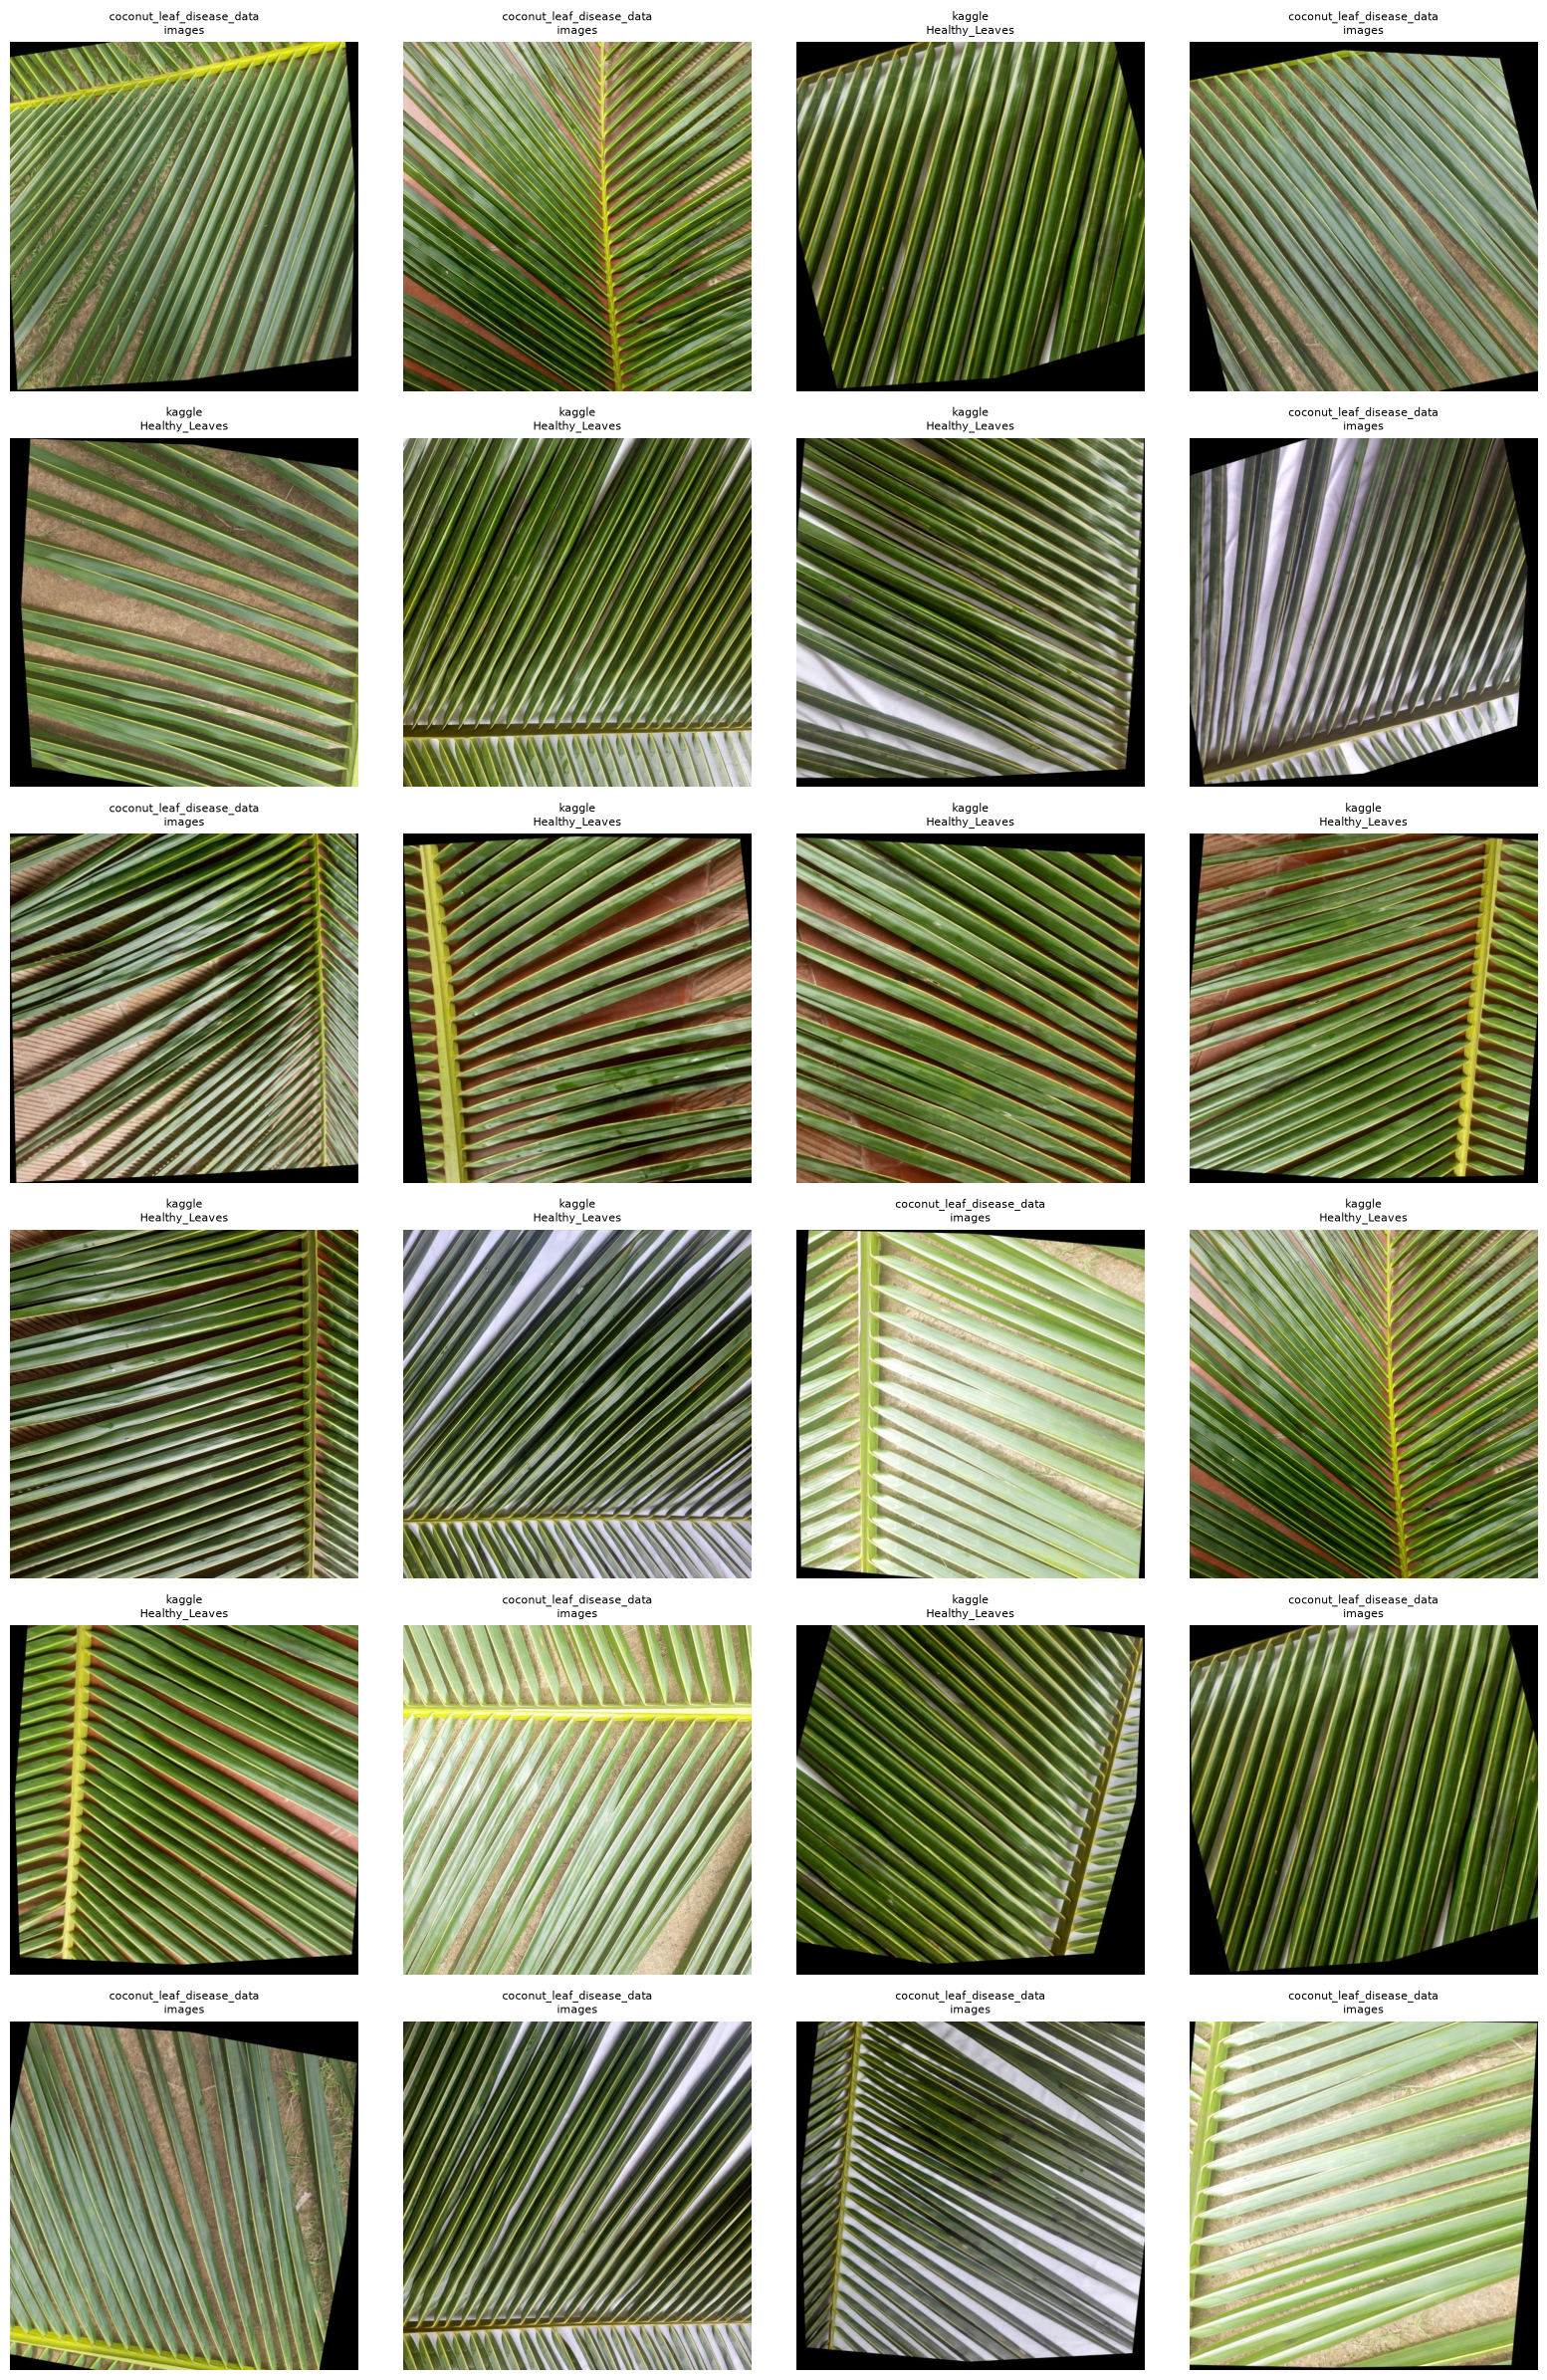

In [7]:
PREVIEW_SOURCE = None  # e.g. "coconut_leaf_disease_data"; None = all healthy candidates
N_PREVIEW = 24

preview_df = healthy_candidates.copy()
if PREVIEW_SOURCE is not None and len(preview_df):
    preview_df = preview_df[preview_df["source_group"] == PREVIEW_SOURCE]

if len(preview_df):
    sample_df = preview_df.sample(min(N_PREVIEW, len(preview_df)), random_state=SEED)
    ncols = 4
    nrows = (len(sample_df) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]
    for ax in axes:
        ax.axis("off")
    for ax, (_, row) in zip(axes, sample_df.iterrows()):
        try:
            img = Image.open(row["path"]).convert("RGB")
            ax.imshow(img)
            ax.set_title(
                f'{row["source_group"]}\n{Path(row["relative_path"]).parent.name}',
                fontsize=8
            )
            ax.axis("off")
        except Exception:
            pass
    plt.tight_layout()
    plt.show()
else:
    print("No candidate healthy images to preview. Inspect the folder summary and annotations.")

## 6. Detect exact duplicate files

Exact duplicates are identified by SHA-256. This does not detect resized, cropped or recompressed near-duplicates; those need a separate perceptual-hash review.

In [8]:
def sha256_file(file_path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(file_path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()

hash_records = []
for p in inventory["path"].tolist() if len(inventory) else []:
    try:
        hash_records.append({"path": p, "sha256": sha256_file(p)})
    except OSError as exc:
        print("Hash failed:", p, exc)

hash_df = pd.DataFrame(hash_records)
if len(hash_df):
    duplicate_groups = (
        hash_df.groupby("sha256")
        .filter(lambda g: len(g) > 1)
        .sort_values("sha256")
    )
    print("Files participating in exact duplicate groups:", len(duplicate_groups))
    display(duplicate_groups.head(50))
else:
    duplicate_groups = pd.DataFrame()

Files participating in exact duplicate groups: 70


,path,sha256
8490,/run/media/sivabharathi/ssd/storage/finalYear/...,08dccc038475aa1d8e777c5d7f9e9d3ef217f1f4f3cd06...
11096,/run/media/sivabharathi/ssd/storage/finalYear/...,08dccc038475aa1d8e777c5d7f9e9d3ef217f1f4f3cd06...
8481,/run/media/sivabharathi/ssd/storage/finalYear/...,0ce7df599ab249d5457794ab2ae799d2a5b04b79531fb2...
11087,/run/media/sivabharathi/ssd/storage/finalYear/...,0ce7df599ab249d5457794ab2ae799d2a5b04b79531fb2...
8486,/run/media/sivabharathi/ssd/storage/finalYear/...,1f25f389c1c3ca371f35836bf560f94d493217d0935dd7...
11092,/run/media/sivabharathi/ssd/storage/finalYear/...,1f25f389c1c3ca371f35836bf560f94d493217d0935dd7...
4325,/run/media/sivabharathi/ssd/storage/finalYear/...,1f4b7cc604b176c278da4be04a1fdb5bb2a1cfa62441f6...
4334,/run/media/sivabharathi/ssd/storage/finalYear/...,1f4b7cc604b176c278da4be04a1fdb5bb2a1cfa62441f6...
8495,/run/media/sivabharathi/ssd/storage/finalYear/...,2442412dc7ed69a4a5a9d50dc8039b1074f107f7a30c47...
9621,/run/media/sivabharathi/ssd/storage/finalYear/...,2442412dc7ed69a4a5a9d50dc8039b1074f107f7a30c47...


## 7. Inspect annotation files (Roboflow / YOLO datasets)

Some downloaded datasets may be object-detection datasets with `train/valid/test/images` and matching `labels/*.txt`. This cell inventories annotation text files. It does not convert bounding boxes into classification labels automatically.

In [9]:
annotation_files = list(RAW_DATA_DIR.rglob("*.txt"))
print("Text annotation files:", len(annotation_files))
for p in annotation_files[:30]:
    print(p.relative_to(RAW_DATA_DIR))

# Optional: inspect a few YOLO label files.
for p in annotation_files[:5]:
    print("\\n---", p.relative_to(RAW_DATA_DIR), "---")
    try:
        print(p.read_text(errors="replace")[:1000])
    except Exception as exc:
        print("Could not read:", exc)

Text annotation files: 1310
coconut_leaf_disease_data/README.dataset.txt
coconut_leaf_disease_data/README.roboflow.txt
coconut_leaf_disease_data/test/labels/LeafRot310_jpg.rf.ef103e603a904e481b846e7d24d00309.txt
coconut_leaf_disease_data/test/labels/LeafRot328_jpg.rf.f273420b24af73b96c29c62e9d8e4a60.txt
coconut_leaf_disease_data/test/labels/LeafRot402_jpg.rf.934fb314b8790b5b5a876a9ca5a3b2b9.txt
coconut_leaf_disease_data/test/labels/LeafRot417_jpg.rf.3069ab979cecb504afb78da2f053cd91.txt
coconut_leaf_disease_data/test/labels/LeafRot479_jpg.rf.80428502c890d35e1ff1cc3f7e272a35.txt
coconut_leaf_disease_data/test/labels/LeafRot486_jpg.rf.d61180401562b79b9ae201e7e09f91bd.txt
coconut_leaf_disease_data/test/labels/LeafRot505_jpg.rf.c8125d0f74d6b20aba9f0ea3b2544920.txt
coconut_leaf_disease_data/test/labels/LeafRot543_jpg.rf.98e0592d473a8e1ca28f2913aa36c1ea.txt
coconut_leaf_disease_data/test/labels/LeafRot557_jpg.rf.bf0c8f1e36416ff539544612f233e10b.txt
coconut_leaf_disease_data/test/labels/LeafRo

## 8. Configure the six-class mapping — manual review required

The existing Mendeley disease dataset remains the source for the five disease classes. Update the folder names below after checking the inventory.

For healthy images, map only verified healthy-labelled folders. Do not map an entire source folder to `healthy`.

The `source_group` and `relative_path` columns above show the exact folder structure to use.

In [10]:
# Edit these keys to match the actual folders discovered in Section 4.
# Keys are substrings of inventory['relative_path'] (case-insensitive).
# Values are canonical class names.
#
# IMPORTANT:
# - Keep the original Mendeley disease data as your disease source.
# - Add only explicitly labelled / manually verified healthy image folders.
# - Do not map ambiguous or unlabelled crown photographs until manually reviewed.

CLASS_RULES = {
    # Healthy class examples — replace with exact verified folder substrings:
    # "coconut_leaf_disease_data/train/healthy": "healthy",
    # "coconut_leaf_disease_data/valid/healthy": "healthy",
    # "coconut_leaf_disease_data/test/healthy": "healthy",

    # Disease class examples — edit to match your real folder names:
    # "bud_root_dropping": "bud_root_dropping",
    # "bud_rot": "bud_rot",
    # "gray_leaf_spot": "gray_leaf_spot",
    # "leaf_rot": "leaf_rot",
    # "stem_bleeding": "stem_bleeding",
}

CANONICAL_CLASSES = [
    "healthy",
    "bud_root_dropping",
    "bud_rot",
    "gray_leaf_spot",
    "leaf_rot",
    "stem_bleeding",
]

def assign_class(relative_path):
    rel = relative_path.lower().replace("\\", "/")
    matches = [(key, value) for key, value in CLASS_RULES.items()
               if key.lower() in rel]
    if not matches:
        return None
    # Longest matching rule is the most specific.
    matches.sort(key=lambda item: len(item[0]), reverse=True)
    return matches[0][1]

if len(inventory):
    inventory["class_name"] = inventory["relative_path"].apply(assign_class)
    mapped = inventory[inventory["class_name"].notna()].copy()
    print("Mapped images:", len(mapped))
    display(mapped.groupby(["source_group", "class_name"]).size()
            .unstack(fill_value=0))
    print("Unmapped images:", len(inventory) - len(mapped))
else:
    mapped = pd.DataFrame()
    print("No images found.")

Mapped images: 0


class_name
source_group


Unmapped images: 12245


## 9. Create a review manifest before copying

Export a CSV for manual review. Set `review_status` to `approved` only after checking the image and its source label. For healthy whole-tree images, also record the image type as `tree`; close-up leaves should be `leaf`.

The generated manifest is metadata only; no image files are copied in this step.

In [11]:
if len(mapped):
    manifest = mapped[[
        "path", "relative_path", "source_group", "class_name",
        "width", "height", "file_size_bytes"
    ]].copy()
    manifest["image_type"] = ""  # fill with leaf / tree / other
    manifest["review_status"] = "pending"
    manifest["review_notes"] = ""
    manifest_path = RAW_DATA_DIR / "coconut_health_v2_review_manifest.csv"
    manifest.to_csv(manifest_path, index=False)
    print("Review manifest saved:", manifest_path.resolve())
    display(manifest.head())
else:
    print("No mapped images yet. Configure CLASS_RULES and rerun Sections 8–9.")

No mapped images yet. Configure CLASS_RULES and rerun Sections 8–9.


## 10. Build the prepared dataset after review

This cell is intentionally disabled by default. After manually editing the review manifest:
1. Set each accepted image's `review_status` to `approved`.
2. Confirm its `class_name`.
3. Ensure all six class names are spelled exactly as in `CANONICAL_CLASSES`.
4. Check source licences and attribution.
5. Keep images from the same original tree/source group together when splitting.

The cell copies approved images into a staging directory and writes a new manifest. It never deletes or edits raw files.

In [12]:
BUILD_DATASET = False  # Change to True only after completing manual review.

if not BUILD_DATASET:
    print("Dataset build is disabled. Review the CSV first, then set BUILD_DATASET = True.")
else:
    manifest_path = RAW_DATA_DIR / "coconut_health_v2_review_manifest.csv"
    reviewed = pd.read_csv(manifest_path)

    approved = reviewed[reviewed["review_status"].astype(str).str.lower() == "approved"].copy()
    unknown_classes = sorted(set(approved["class_name"]) - set(CANONICAL_CLASSES))
    if unknown_classes:
        raise ValueError(f"Unknown class names: {unknown_classes}")

    missing_classes = sorted(set(CANONICAL_CLASSES) - set(approved["class_name"]))
    if missing_classes:
        raise ValueError(f"These classes have no approved images: {missing_classes}")

    # Avoid accidental overwrite of a previous prepared dataset.
    if PREPARED_DIR.exists():
        raise FileExistsError(
            f"{PREPARED_DIR} already exists. Rename/archive it before building a new version."
        )

    copied_rows = []
    for idx, row in approved.reset_index(drop=True).iterrows():
        src = Path(row["path"])
        cls = row["class_name"]
        ext = src.suffix.lower()
        # Unique stable filename prevents collisions between source datasets.
        token = hashlib.sha1(str(src).encode()).hexdigest()[:12]
        dest_dir = PREPARED_DIR / cls
        dest_dir.mkdir(parents=True, exist_ok=True)
        dest = dest_dir / f"{idx:06d}_{token}{ext}"
        shutil.copy2(src, dest)

        copied_rows.append({
            "prepared_path": str(dest),
            "source_path": str(src),
            "source_group": row["source_group"],
            "class_name": cls,
            "image_type": row.get("image_type", ""),
            "sha256": sha256_file(dest),
        })

    prepared_manifest = pd.DataFrame(copied_rows)
    prepared_manifest.to_csv(PREPARED_DIR / "manifest.csv", index=False)
    print("Prepared images:", len(prepared_manifest))
    display(prepared_manifest.groupby("class_name").size())
    print("Prepared dataset:", PREPARED_DIR.resolve())

Dataset build is disabled. Review the CSV first, then set BUILD_DATASET = True.


## 11. Final checks before model training

Do not train until all checks below are satisfied.

- [ ] Healthy images are genuinely coconut (*Cocos nucifera*).
- [ ] Healthy labels have been verified; visually green is not sufficient proof of whole-tree health.
- [ ] Leaf and whole-tree image counts are known separately.
- [ ] All five Mendeley disease labels are mapped correctly.
- [ ] No exact duplicates cross dataset splits.
- [ ] Images from the same tree / capture session are grouped into one split.
- [ ] No augmented versions of the same original image appear across splits.
- [ ] Class counts and source licences are documented.
- [ ] Validation and test sets include representative healthy leaf images; if tree images will be accepted in the app, test them separately too.

**Recommended next step:** after this audit, create a separate training notebook that loads the approved six-class dataset, uses a source/tree-grouped split, trains MobileNetV3Small, and evaluates leaf-versus-tree performance separately.

In [13]:
print("Healthy candidate count by source:")

display(
    healthy_candidates
    .groupby("source_group")
    .size()
    .reset_index(name="healthy_candidates")
)

print("\nHealthy candidate folder distribution:")

display(
    healthy_candidates
    .groupby(["source_group", "parent_folder"])
    .size()
    .reset_index(name="count")
)

Healthy candidate count by source:


,source_group,healthy_candidates
0,coconut_leaf_disease_data,123
1,kaggle,123



Healthy candidate folder distribution:


,source_group,parent_folder,count
0,coconut_leaf_disease_data,images,123
1,kaggle,Healthy_Leaves,123


In [14]:
from pathlib import Path

roboflow_dir = RAW_DATA_DIR / "coconut_leaf_disease_data"

print("YAML CONFIGURATION FILES")

for p in roboflow_dir.rglob("*"):
    if p.is_file() and p.suffix.lower() in [".yaml", ".yml"]:
        print("\nFILE:", p.relative_to(roboflow_dir))
        print(p.read_text(errors="replace")[:5000])


print("\nDATASET README FILES")

for name in ["README.dataset.txt", "README.roboflow.txt"]:
    p = roboflow_dir / name

    if p.exists():
        print(f"\n--- {name} ---")
        print(p.read_text(errors="replace")[:5000])

YAML CONFIGURATION FILES

FILE: data.yaml
names:
- bud root
- cercospora
- healthy
- leaf rot
- pestalotiopsis
nc: 5
roboflow:
  license: CC BY 4.0
  project: coconut-leaf-disease-j9noh
  url: https://universe.roboflow.com/jamess-workspace-cjnrd/coconut-leaf-disease-j9noh/dataset/3
  version: 3
  workspace: jamess-workspace-cjnrd
test: ../test/images
train: ../train/images
val: ../valid/images


DATASET README FILES

--- README.dataset.txt ---
# Coconut-Leaf-Disease > 2026-07-17 4:00pm
https://universe.roboflow.com/jamess-workspace-cjnrd/coconut-leaf-disease-j9noh

Provided by a Roboflow user
License: CC BY 4.0



--- README.roboflow.txt ---

Coconut-Leaf-Disease - v3 2026-07-17 4:00pm

This dataset was exported via roboflow.com on July 18, 2026 at 3:57 AM GMT

Roboflow is an end-to-end computer vision platform that helps you
* collaborate with your team on computer vision projects
* collect & organize images
* understand and search unstructured image data
* annotate, and create datase

In [15]:
from collections import Counter

healthy_annotations = []

for split in ["train", "valid", "test"]:

    image_dir = roboflow_dir / split / "images"
    label_dir = roboflow_dir / split / "labels"

    if not image_dir.exists():
        continue

    for image_path in image_dir.iterdir():

        if not image_path.is_file():
            continue

        if "healthy" not in image_path.name.lower():
            continue

        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            status = "MISSING_ANNOTATION"
            class_ids = []

        else:
            lines = [
                line.strip()
                for line in label_path.read_text().splitlines()
                if line.strip()
            ]

            class_ids = [line.split()[0] for line in lines]
            status = "ANNOTATED"

        healthy_annotations.append({
            "split": split,
            "filename": image_path.name,
            "annotation_status": status,
            "class_ids": class_ids
        })

healthy_annotation_df = pd.DataFrame(healthy_annotations)

display(healthy_annotation_df.head(20))

print("\nAnnotation status:")
display(healthy_annotation_df["annotation_status"].value_counts())

,split,filename,annotation_status,class_ids
0,train,Healthy_leaf_122_jpg.rf.7da377aab6f1443b42cc6b...,ANNOTATED,"[2, 2]"
1,train,Healthy_leaf_123_jpg.rf.bed4e70e1bc45de83d1854...,ANNOTATED,[2]
2,train,Healthy_leaf_12_jpg.rf.fe6cb5d932c84c317692d71...,ANNOTATED,[2]
3,train,Healthy_leaf_14_jpg.rf.c07a35c162b70adc466fec8...,ANNOTATED,[2]
4,train,Healthy_leaf_16_jpg.rf.528a5d84cb41723b12636fd...,ANNOTATED,[2]
5,train,Healthy_leaf_18_jpg.rf.e408a355243422c8ba51bea...,ANNOTATED,[2]
6,train,Healthy_leaf_19_jpg.rf.cdec7ffbdac54eba7e6e60f...,ANNOTATED,[2]
7,train,Healthy_leaf_1_jpg.rf.8b2b72d4de42a380d63038a2...,ANNOTATED,"[2, 2]"
8,train,Healthy_leaf_20_jpg.rf.ce52bdea474f71b761ec6e1...,ANNOTATED,[2]
9,train,Healthy_leaf_21_jpg.rf.e30c67d9ba9555d043f9a30...,ANNOTATED,[2]



Annotation status:


annotation_status
ANNOTATED    123
Name: count, dtype: int64